# Email Spam Classifier

Classifying SMS/email messages as **spam** or **ham** using classical NLP
(cleaning → tokenising → stop-word removal → lemmatisation → TF-IDF) and four
classifiers compared on cross-validated accuracy.

**Dataset:** `spam_ham_dataset.csv` (5,171 messages) — included in this repo.

## 1. Imports

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn import metrics
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.pipeline import Pipeline

import joblib

for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4"]:
    nltk.download(pkg, quiet=True)

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## 2. Load the data

Path is relative to the repo, so it runs anywhere.

In [2]:
df = pd.read_csv("spam_ham_dataset.csv")

# First column is an unnamed index; keep only label / text / label_num
df = df.drop(columns=[c for c in df.columns if c.startswith("Unnamed")])
df = df.rename(columns={"label": "Target", "text": "Text"})

print(df.shape)
df.head()

(5171, 3)


,Target,Text,label_num
0,ham,Subject: enron methanol ; meter # : 988291\r\n...,0
1,ham,"Subject: hpl nom for january 9 , 2001\r\n( see...",0
2,ham,"Subject: neon retreat\r\nho ho ho , we ' re ar...",0
3,spam,"Subject: photoshop , windows , office . cheap ...",1
4,ham,Subject: re : indian springs\r\nthis deal is t...,0


### Confirm what the target values mean

In [3]:
print(df["Target"].value_counts())
# label_num is already the 0/1 encoding: 1 == spam
print(pd.crosstab(df["Target"], df["label_num"]))

Target
ham     3672
spam    1499
Name: count, dtype: int64
label_num     0     1
Target               
ham        3672     0
spam          0  1499


## 3. Exploratory data analysis

The classes are clearly imbalanced, which matters for how we read accuracy later.

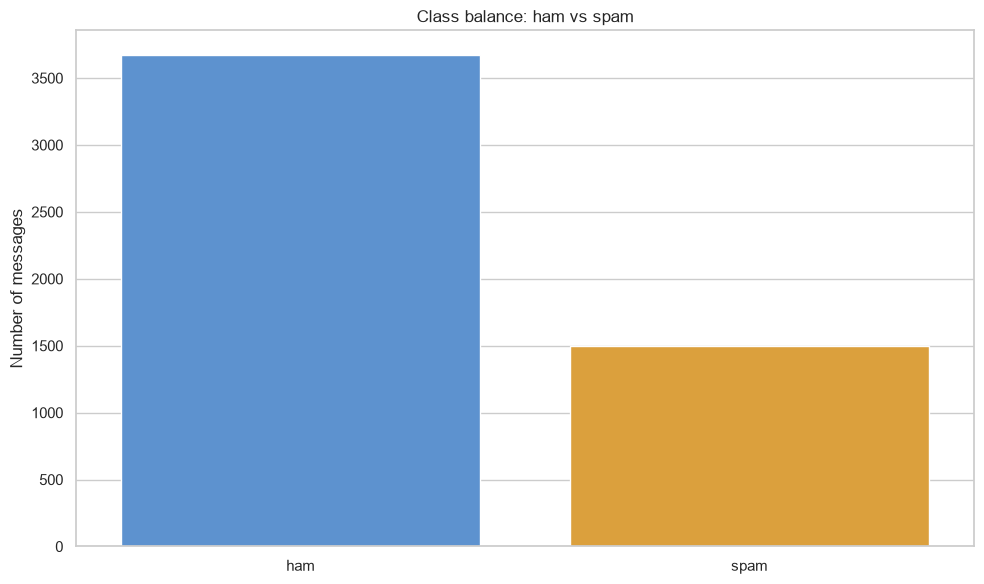

In [4]:
plt.figure(figsize=(10, 6))
ax = sns.countplot(data=df, x="Target", hue="Target",
                   palette=["#4A90E2", "#F5A623"], legend=False)
ax.set_title("Class balance: ham vs spam")
ax.set_xlabel("")
ax.set_ylabel("Number of messages")
plt.tight_layout()
plt.show()

In [5]:
df["Num_of_Char"] = df["Text"].apply(len)
df["Num_of_Words"] = df["Text"].apply(lambda t: len(nltk.word_tokenize(t)))
df["Num_of_Sentences"] = df["Text"].apply(lambda t: len(nltk.sent_tokenize(t)))

df[["Num_of_Char", "Num_of_Words", "Num_of_Sentences"]].describe()

,Num_of_Char,Num_of_Words,Num_of_Sentences
count,5171.000000,5171.000000,5171.000000
mean,1048.391994,229.181009,13.121253
std,1528.513435,336.487397,27.541637
min,11.000000,2.000000,1.000000
25%,244.000000,52.000000,4.000000
50%,540.000000,122.000000,7.000000
75%,1237.000000,283.500000,15.000000
max,32258.000000,8863.000000,1204.000000


In [6]:
# Spam messages are markedly longer than ham on every one of these measures
df.groupby("Target")[["Num_of_Char", "Num_of_Words", "Num_of_Sentences"]].mean().round(1)

,Num_of_Char,Num_of_Words,Num_of_Sentences
Target,,,
ham,977.0,226.2,11.4
spam,1223.3,236.4,17.2


### Remove length outliers

All three length measures are filtered together. The masks are combined with
`&=` rather than applied one at a time, so a row has to fall inside the IQR
range on characters, words **and** sentences to survive.

In [7]:
length_cols = ["Num_of_Char", "Num_of_Words", "Num_of_Sentences"]

mask = pd.Series(True, index=df.index)
for col in length_cols:
    Q1, Q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    IQR = Q3 - Q1
    mask &= df[col].between(Q1 - 1.5 * IQR, Q3 + 1.5 * IQR)

df_clean = df[mask].copy().reset_index(drop=True)
print(f"kept {len(df_clean)} of {len(df)} rows")
print(df_clean["Target"].value_counts())

kept 4539 of 5171 rows
Target
ham     3317
spam    1222
Name: count, dtype: int64


## 4. Text preprocessing

In [8]:
def clean_text(text):
    """Strip everything that is not a letter and normalise whitespace."""
    text = re.sub("[^a-zA-Z]", " ", text)
    return " ".join(text.lower().split())


df_clean["Clean_Text"] = df_clean["Text"].apply(clean_text)
df_clean[["Text", "Clean_Text"]].head(3)

,Text,Clean_Text
0,Subject: enron methanol ; meter # : 988291\r\n...,subject enron methanol meter this is a follow ...
1,"Subject: hpl nom for january 9 , 2001\r\n( see...",subject hpl nom for january see attached file ...
2,"Subject: neon retreat\r\nho ho ho , we ' re ar...",subject neon retreat ho ho ho we re around to ...


In [9]:
df_clean["Tokenized"] = df_clean["Clean_Text"].apply(nltk.word_tokenize)
df_clean["Tokenized"].head(3)

0    [subject, enron, methanol, meter, this, is, a,...
1    [subject, hpl, nom, for, january, see, attache...
2    [subject, neon, retreat, ho, ho, ho, we, re, a...
Name: Tokenized, dtype: object

In [10]:
stop_words = set(stopwords.words("english"))


def remove_stopwords(tokens):
    return [t for t in tokens if t not in stop_words]


df_clean["No_Stopwords"] = df_clean["Tokenized"].apply(remove_stopwords)
df_clean[["Tokenized", "No_Stopwords"]].head(2)

,Tokenized,No_Stopwords
0,"[subject, enron, methanol, meter, this, is, a,...","[subject, enron, methanol, meter, follow, note..."
1,"[subject, hpl, nom, for, january, see, attache...","[subject, hpl, nom, january, see, attached, fi..."


In [11]:
lemmatizer = WordNetLemmatizer()


def lemmatize(tokens):
    return [lemmatizer.lemmatize(t, pos="v") for t in tokens]


df_clean["Lemmatized"] = df_clean["No_Stopwords"].apply(lemmatize)
df_clean[["No_Stopwords", "Lemmatized"]].head(2)

,No_Stopwords,Lemmatized
0,"[subject, enron, methanol, meter, follow, note...","[subject, enron, methanol, meter, follow, note..."
1,"[subject, hpl, nom, january, see, attached, fi...","[subject, hpl, nom, january, see, attach, file..."


### Build the corpus

Tokens are rejoined with a **space**. `''.join` would run each message's words
together (`"free money now"` → `"freemoneynow"`), and the vocabulary TF-IDF
counts is built from those tokens, so gluing them together would destroy it.

In [12]:
corpus = [" ".join(tokens) for tokens in df_clean["Lemmatized"]]
print(corpus[:2])

['subject enron methanol meter follow note give monday preliminary flow data provide daren please override pop daily volume presently zero reflect daily activity obtain gas control change need asap economics purpose', 'subject hpl nom january see attach file hplnol xls hplnol xls']


## 5. Vectorise with TF-IDF

In [13]:
tfidf = TfidfVectorizer()
X = tfidf.fit_transform(corpus)
print("TF-IDF matrix:", X.shape)

TF-IDF matrix: (4539, 26239)


## 6. Train / test split

`label_num` is used directly — running a `LabelEncoder` on `df` (rather than on
`df_clean`) while `y` came from `df_clean` left the two out of sync.

In [14]:
y = df_clean["label_num"].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print(X_train.shape, X_test.shape)

(3631, 26239) (908, 26239)


## 7. Train and compare four classifiers

In [15]:
classifiers = [
    MultinomialNB(),
    LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    RandomForestClassifier(random_state=RANDOM_STATE),
    KNeighborsClassifier(),
    SVC(),
]
names = ["NaiveBayes", "LogisticRegression", "RandomForest", "KNeighbours", "SVC"]

for name, model in zip(names, classifiers):
    model.fit(X_train, y_train)
print("trained:", ", ".join(names))

trained: NaiveBayes, LogisticRegression, RandomForest, KNeighbours, SVC


In [16]:
# 10-fold cross-validation on the training split, scored by F1 on the spam
# class. Accuracy is not used as the headline metric: ham outnumbers spam ~73/27
# here, so always predicting "ham" already scores ~0.73 and accuracy hides
# dropped spam. F1 balances precision and recall on the class that matters.
cv_scores = {}
for name, model in zip(names, classifiers):
    scores = cross_val_score(model, X_train, y_train, scoring="f1", cv=10)
    cv_scores[name] = scores.mean()
    print(f"{name:<18} {scores.mean():.4f}")

NaiveBayes         0.8056


LogisticRegression 0.9728


RandomForest       0.9631


KNeighbours        0.9181


SVC                0.9765


### Held-out evaluation

Every row scores itself. The loop takes the model **name** and the fitted
**object** together, and the score is read from that object, so no row can
inherit the accuracy of another model.

In [17]:
rows = []
for name, i in zip(names, classifiers):
    pred_test = i.predict(X_test)
    rows.append({
        "Model": name,
        "Precision": metrics.precision_score(y_test, pred_test, pos_label=1),
        "Recall": metrics.recall_score(y_test, pred_test, pos_label=1),
        "F1": metrics.f1_score(y_test, pred_test, pos_label=1),
        "CV F1": cv_scores[name],
        "Train accuracy": i.score(X_train, y_train),
        "Test accuracy": i.score(X_test, y_test),
    })

results = pd.DataFrame(rows).set_index("Model").round(4)
results

,Precision,Recall,F1,CV F1,Train accuracy,Test accuracy
Model,,,,,,
NaiveBayes,1.0000,0.7787,0.8756,0.8056,0.9581,0.9405
LogisticRegression,0.9488,0.9877,0.9679,0.9728,0.9967,0.9824
RandomForest,0.9407,0.9754,0.9577,0.9631,1.0000,0.9769
KNeighbours,0.9737,0.9098,0.9407,0.9181,0.9758,0.9692
SVC,0.9528,0.9918,0.9719,0.9765,1.0000,0.9846


In [18]:
results.style.background_gradient(cmap="Purples").format("{:.4f}")

,Precision,Recall,F1,CV F1,Train accuracy,Test accuracy
Model,,,,,,
NaiveBayes,1.0000,0.7787,0.8756,0.8056,0.9581,0.9405
LogisticRegression,0.9488,0.9877,0.9679,0.9728,0.9967,0.9824
RandomForest,0.9407,0.9754,0.9577,0.9631,1.0000,0.9769
KNeighbours,0.9737,0.9098,0.9407,0.9181,0.9758,0.9692
SVC,0.9528,0.9918,0.9719,0.9765,1.0000,0.9846


In [19]:
best_name = results["F1"].idxmax()
best_model = classifiers[names.index(best_name)]
print(f"Best model by F1 on the spam class: {best_name} "
      f"(F1 {results.loc[best_name, 'F1']:.4f}, "
      f"test accuracy {results.loc[best_name, 'Test accuracy']:.4f})")
print(f"Trivial 'always ham' baseline: {1 - y_test.mean():.4f} test accuracy")

Best model by F1 on the spam class: SVC (F1 0.9719, test accuracy 0.9846)
Trivial 'always ham' baseline: 0.7313 test accuracy


### Confusion matrix and per-class report for the best model

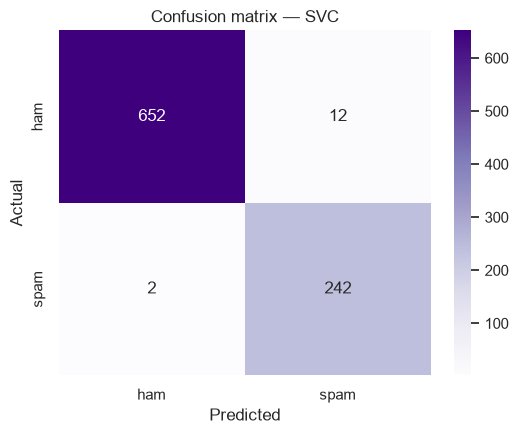

In [20]:
pred = best_model.predict(X_test)

cm = confusion_matrix(y_test, pred)
plt.figure(figsize=(5.5, 4.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Purples",
            xticklabels=["ham", "spam"], yticklabels=["ham", "spam"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title(f"Confusion matrix — {best_name}")
plt.tight_layout()
plt.show()

In [21]:
print(classification_report(y_test, pred, target_names=["ham", "spam"]))

              precision    recall  f1-score   support

         ham       1.00      0.98      0.99       664
        spam       0.95      0.99      0.97       244

    accuracy                           0.98       908
   macro avg       0.97      0.99      0.98       908
weighted avg       0.99      0.98      0.98       908



## 8. Save the model and use it on new messages

In [22]:
# Persist the fitted vectoriser alongside the model — both are needed to predict
joblib.dump({"model": best_model, "vectorizer": tfidf, "name": best_name},
            "spam_classifier.joblib")
print("saved spam_classifier.joblib")

saved spam_classifier.joblib


In [23]:
bundle = joblib.load("spam_classifier.joblib")
_model, _vec = bundle["model"], bundle["vectorizer"]


def predict_message(message):
    '''Return ('spam'|'ham', score) for a raw message string.

    SVC is fitted without probability=True, so it has no predict_proba;
    for those models the signed decision-function margin is reported instead.
    '''
    tokens = lemmatize(remove_stopwords(nltk.word_tokenize(clean_text(message))))
    vec = _vec.transform([" ".join(tokens)])
    label = int(_model.predict(vec)[0])

    if hasattr(_model, "predict_proba"):
        score = f"p={_model.predict_proba(vec)[0][label]:.3f}"
    else:
        score = f"margin={float(_model.decision_function(vec)[0]):+.2f}"

    return ("spam" if label == 1 else "ham"), score


samples = [
    "Congratulations! You have won a FREE 1000 pound prize. Call now to claim!",
    "Hey, are we still meeting for lunch tomorrow at 1?",
    "URGENT: Your account will be suspended. Verify your details immediately.",
]
for s in samples:
    label, score = predict_message(s)
    print(f"{label:<5} ({score:<10})  {s}")

spam  (margin=+0.38)  Congratulations! You have won a FREE 1000 pound prize. Call now to claim!
ham   (margin=-0.28)  Hey, are we still meeting for lunch tomorrow at 1?
spam  (margin=+0.32)  URGENT: Your account will be suspended. Verify your details immediately.
